# 3.4 Paradigma y 3.5 Metodología y selección del modelo

> Borrador de las secciones 3.4 y 3.5 (Jose). Se integra en `model_development.ipynb`.

**Paradigma (3.4):** aprendizaje supervisado, clasificación binaria. Al momento de la firma se estima la probabilidad de que el contrato termine con el plazo ampliado (`y`). Hay etiqueta histórica para 2019-2025 y la decisión del usuario es ordenar contratos para revisarlos, así que un modelo que puntúa y ordena es lo que se necesita.

**Metodología (3.5):**
- Split temporal: train 2019-2023, test 2024 y 2025 como deriva. Solo contratos maduros.
- Dentro del train, folds temporales de ventana creciente: se entrena con los años anteriores y se valida en 2021, 2022 y 2023.
- Cinco modelos del curso, con búsqueda aleatoria de hiperparámetros sobre esos folds y un tope de 15 minutos por modelo. kNN y SVM sobre una submuestra de 20.000 contratos.
- Métrica de selección: PR-AUC medio de los folds. El test 2024 no se usa para elegir.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # el borrador vive en notebooks/; el notebook final, en la raiz de final-project/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
from src import modelado as MD, modelo as MO

RECALCULAR = False     # True vuelve a correr la busqueda (unos 12 min) y reescribe resultados/j3_busqueda_*
if RECALCULAR:
    import subprocess
    subprocess.run([sys.executable, "-m", "src.modelado"], cwd=RAIZ, check=True)
busq = json.loads((RES / "j3_busqueda_resumen.json").read_text(encoding="utf-8"))
j3 = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))

## Folds temporales

**Decisión:** validación con ventana creciente y no `KFold` aleatorio.
- **Por qué:** el modelo se va a usar con contratos futuros, y el SECOP II cambió mucho entre años (más contratación directa, más personas naturales). Un fold aleatorio mezclaría años y daría una estimación optimista.
- **Evidencia:** la tasa de positivos sube de 0,273 en el train del primer fold a 0,300 en la validación de 2023, y en el test 2024 baja a 0,247.

In [2]:
base = pd.read_parquet(BASE_V1, columns=["anio_firma", "y", "eval_madura", "nit_entidad", "eval_dur_planeada_dias"])
idx_tr, _ = E.split_temporal(base, config.ANIO_TEST)
an, y = base.loc[idx_tr, "anio_firma"].to_numpy(), base.loc[idx_tr, "y"].to_numpy()
pd.DataFrame([{"validación": int(an[v][0]), "años de train": f"{an[t].min()}-{an[t].max()}", "n train": len(t),
               "tasa train": y[t].mean(), "n validación": len(v), "tasa validación": y[v].mean()}
              for t, v in E.folds_temporales(an)])

,validación,años de train,n train,tasa train,n validación,tasa validación
0,2021,2019-2020,50482,0.273,56370,0.278
1,2022,2019-2021,106852,0.276,70899,0.295
2,2023,2019-2022,177751,0.283,83498,0.300


## Las reglas simples que hay que superar

- **Tasa base:** el mismo puntaje para todos.
- **Tasa histórica por entidad:** (positivos + m · p0) / (contratos + m); las entidades nuevas reciben p0. El suavizado `m` se elige con los mismos folds temporales: entre los `m` a menos de 0,005 del mejor ROC-AUC, gana el de mejor precisión en el top-k. Con m = 0 el top 1 % se llena de entidades con 1 de 1 positivos.

In [3]:
tm = pd.read_csv(RES / "j1_v1_elegir_m.csv")
display(tm.style.format(precision=4).apply(lambda r: ["background-color: #dbe9f6" if r["elegida"] else "" for _ in r], axis=1))

,m,roc_auc,pr_auc,p@1%,p@5%,p@10%,p_topk_media,elegida
0,0,0.6642,0.4838,0.7366,0.7310,0.6115,0.6931,False
1,1,0.6637,0.4868,0.7769,0.7375,0.6153,0.7099,False
2,2,0.6631,0.4877,0.7798,0.7536,0.6159,0.7164,False
3,5,0.6617,0.4885,0.7798,0.7608,0.6307,0.7238,False
4,10,0.6604,0.4883,0.7798,0.7643,0.6340,0.7260,True
5,20,0.6589,0.4882,0.7798,0.7658,0.6403,0.7287,False
6,50,0.6558,0.4873,0.7798,0.7675,0.6425,0.7299,False
7,100,0.6531,0.4862,0.7798,0.7701,0.6475,0.7325,False


## Búsqueda de hiperparámetros

,n_train,n_iter,segundos,pr_auc_cv,pr_auc_cv_std,roc_auc_cv
rf,"261,249",12,300,0.5781,0.0130,0.7567
hgb,"261,249",25,287,0.5765,0.0046,0.7620
arbol,"261,249",30,51,0.5318,0.0104,0.7321
svm,"20,000",10,45,0.5225,0.0407,0.6904
knn,"20,000",15,17,0.5169,0.0471,0.6925


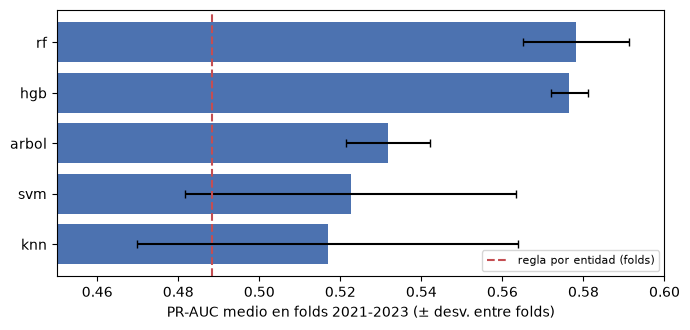

hgb    {'l2_regularization': 0.002259279742015696, 'learning_rate': 0.034003508264422166, 'max_features': 0.5, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}
arbol  {'min_samples_leaf': 200, 'max_depth': 12, 'criterion': 'entropy', 'class_weight': None}
rf     {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': None}
knn    {'weights': 'distance', 'p': 1, 'n_neighbors': 100}
svm    {'C': 1.5751320499779735, 'gamma': 0.01}


In [4]:
t = pd.DataFrame(busq).T[["n_train", "n_iter", "segundos", "pr_auc_cv", "pr_auc_cv_std", "roc_auc_cv"]].astype(float)
t = t.sort_values("pr_auc_cv", ascending=False)
display(t.style.format({"n_train": "{:,.0f}", "n_iter": "{:.0f}", "segundos": "{:.0f}", "pr_auc_cv": "{:.4f}",
                        "pr_auc_cv_std": "{:.4f}", "roc_auc_cv": "{:.4f}"}))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(t.index[::-1], t["pr_auc_cv"][::-1], xerr=t["pr_auc_cv_std"][::-1], color="#4C72B0", capsize=3)
ax.axvline(tm.loc[tm["elegida"], "pr_auc"].iloc[0], color="#C44E52", ls="--", label="regla por entidad (folds)")
ax.set_xlim(0.45, 0.6); ax.set_xlabel("PR-AUC medio en folds 2021-2023 (± desv. entre folds)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for k, v in busq.items():
    print(f"{k:6s} {v['mejores_parametros']}")

**Interpretación:** los dos ensambles de árboles (HGB y RF) quedan arriba y prácticamente empatados (0,5765 y 0,5781). El árbol solo, kNN y SVM quedan claramente por debajo; kNN y SVM además se entrenaron con 20.000 contratos y varían mucho entre folds. Todas las búsquedas terminaron dentro del tope de 15 minutos.

**Decisión: el modelo final es el HGB.**
- **Alternativas:** Random Forest, que tiene un PR-AUC medio un poco mayor.
- **Por qué:** la diferencia (0,0016) es menor que la desviación entre folds del RF (0,013), así que están empatados. El HGB es más estable entre folds (desviación de 0,0046), pesa unos 3 MB y tiene `decision_function`, que la app usa para verificar que los valores SHAP suman la salida del modelo.
- **Evidencia:** tabla y gráfica de arriba. Early stopping desactivado (regla 4).

## Categorías nativas frente a códigos ordinales (HGB, mismos hiperparámetros)

In [5]:
nat = pd.DataFrame({k: {"PR-AUC cv": v["pr_auc_cv"], "ROC-AUC cv": v["roc_auc_cv"], "PR-AUC por fold (2021, 2022, 2023)": v["pr_auc_por_fold"]}
                    for k, v in j3["nativas_vs_ordinal"].items()}).T
display(nat)

,PR-AUC cv,ROC-AUC cv,"PR-AUC por fold (2021, 2022, 2023)"
ordinal,0.576,0.762,"[0.5809, 0.5783, 0.5702]"
nativas,0.580,0.765,"[0.586, 0.5772, 0.5762]"


**Decisión:** códigos ordinales (opción b del plan).
- **Por qué:** las nativas ganan +0,003 de PR-AUC medio y no en todos los folds (pierden en 2022); con ellas SHAP no es confiable y la app no explicaría. Se gana explicabilidad exacta a cambio de una diferencia que está dentro del ruido.
- **Evidencia:** tabla de arriba; error de aditividad de SHAP de 7e-13 con los códigos (sección 3.6).

## El modelo final

`src/modelo.py: construir_pipeline()` devuelve el `Pipeline` del modelo v1 sin ajustar (lo usa también el monitoreo de la sección 3.9). Se entrena con 2019-2023 y se guarda en `models/modelo_prorroga_v1.joblib` con su `.json`.

In [6]:
from src import modelo_io
pipe, meta = modelo_io.cargar_modelo(config.MODELS / "modelo_prorroga_v1.joblib")
print(meta["version"], "|", meta["modelo"]["clase"], "| categorías nativas:", meta["modelo"]["categorias_nativas"])
print("Hiperparámetros:", meta["modelo"]["hiperparametros"])
print("Train:", meta["datos"]["anios_train"], f"{meta['datos']['n_train']:,} contratos, tasa {meta['datos']['tasa_base_train']}")
pipe

v1.0 | HistGradientBoostingClassifier | categorías nativas: False
Hiperparámetros: {'early_stopping': False, 'l2_regularization': 0.002259279742015696, 'learning_rate': 0.034003508264422166, 'max_features': 0.5, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}
Train: [2019, 2023] 261,249 contratos, tasa 0.2887


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](39,)","['tipo_de_contrato','modalidad_de_contratacion', 'justificacion_modalidad_de',...,'p_respuestas_externas', 'p_conteo_de_respuestas_a_ofertas','p_proveedores_unicos_con']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,39
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('dur', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature nam